# 03 · Bayesian time-series model: projecting renewable shares to 2030

**Question:** if the dynamics seen since 1990 continue, what share of world energy supply will come from
(a) *modern renewables* (hydro + solar, wind & other) and (b) *all renewables* (adding biofuels & waste) in 2030, and **how uncertain is that number?**

**What this is and is not.** This is a *statistical extrapolation* of an observed series with honest uncertainty.
It is **not** a policy scenario. The IEA's scenario-based outlooks model policies, prices and technologies explicitly; a trend model cannot.

**Heavy computation** (MCMC fits, backtest) lives in `scripts/` and saves to `results/`. This notebook loads and interrogates those results, so it runs in seconds.

In [1]:
import sys; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, arviz as az, xarray as xr
from src.energy import *
from src.model import summarize
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ej = pd.read_csv("../data/processed/tes_by_source_EJ.csv", index_col="year"); ej.columns.name = "source"
SERIES = {"modern_renewables": ("Modern renewables (hydro + solar, wind & other)", MODERN_REN),
          "renewables": ("All renewables (incl. biofuels & waste)", RENEWABLES)}
share = {k: group_share(ej, v[1]) for k, v in SERIES.items()}
COL = {"M0": "#999999", "M1": "#e6a23c", "M2": "#3a86c8"}

## 1. Why model the *logit* of the share
A share is bounded between 0 and 100%. A straight line fitted to a share could one day predict 105%. Modelling
$\text{logit}(p)=\ln\frac{p}{1-p}$ keeps every projection inside (0, 100%) after back-transforming, and makes growth multiplicative on the odds scale, which suits a share that starts small.

## 2. Models compared
| | Model | Idea |
|---|---|---|
| **M0** | Random walk with drift | Naive baseline. Next year = this year + average past change. |
| **M1** | Linear trend + AR(1) errors | $\text{logit}(p_t)=a+b(t-2000)+u_t$, $u_t=\rho u_{t-1}+\varepsilon_t$. One constant slope, so it cannot capture acceleration. |
| **M2** | **Smooth local trend (main model)** | A state-space model where the *slope itself drifts slowly*: <br>$y_t=\mu_t+e_t,\; \mu_t=\mu_{t-1}+\beta_{t-1},\; \beta_t=\beta_{t-1}+z_t$ with $e_t\sim N(0,\sigma_{obs}^2)$, $z_t\sim N(0,\sigma_{slp}^2)$ |

**Why M2 is the main model.** The renewable share was flat for about 15 years, then accelerated. M1 forces one slope on the whole period; M2 lets the slope change and lets the data say how fast.
M2's latent states are integrated out with a **Kalman filter** inside PyMC, so MCMC explores only two parameters. An explicit latent-state version of the same model (cross-checked in §7) gives the same answer.

**Priors (weakly informative, on the logit scale):** $\sigma_{obs}\sim\text{HalfNormal}(0.02)$, $\sigma_{slp}\sim\text{HalfNormal}(0.005)$, initial level centred on the first observation (sd 0.5), initial slope $\sim N(0,0.05^2)$.

## 3. Prior predictive check
Before looking at fits: do these priors generate plausible share paths, or nonsense? Simulating directly from the priors (no data):

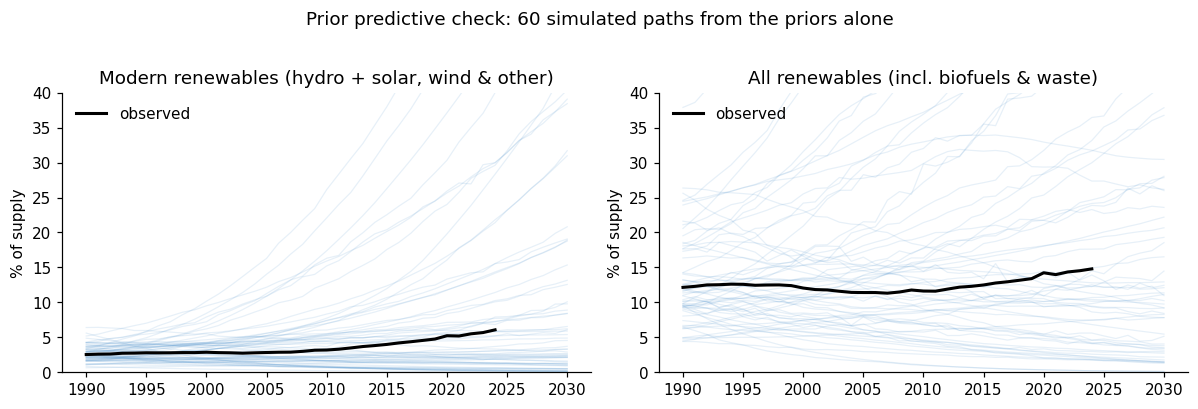

Prior 90% range for the 2030 modern-renewable share: 0.1% to 49.0%


In [2]:
rng = np.random.default_rng(7)
def prior_paths(first_share_pct, n=300, T=41):             # 1990..2030
    y0 = logit(first_share_pct / 100)
    s_slp = np.abs(rng.normal(0, 0.005, n)); s_obs = np.abs(rng.normal(0, 0.02, n))
    mu = rng.normal(y0, 0.5, n); beta = rng.normal(0, 0.05, n)
    out = np.empty((n, T))
    for t in range(T):
        out[:, t] = inv_logit(mu + rng.normal(0, s_obs)) * 100
        mu = mu + beta; beta = beta + rng.normal(0, s_slp)
    return out

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (k, (title, _)) in zip(axes, SERIES.items()):
    pp = prior_paths(share[k].iloc[0])
    ax.plot(range(1990, 2031), pp[:60].T, color="#3a86c8", alpha=0.12, lw=0.8)
    ax.plot(share[k].index, share[k].values, color="k", lw=2, label="observed")
    ax.set(title=title, ylabel="% of supply", ylim=(0, 40)); ax.legend(frameon=False)
fig.suptitle("Prior predictive check: 60 simulated paths from the priors alone", y=1.02)
plt.tight_layout(); plt.show()
lo, hi = np.percentile(prior_paths(share['modern_renewables'].iloc[0])[:, -1], [5, 95])
print(f"Prior 90% range for the 2030 modern-renewable share: {lo:.1f}% to {hi:.1f}%")

The priors are **deliberately diffuse**: the 90% prior range for the 2030 share (printed above) spans from almost zero to roughly half of world supply, far wider than anything plausible. That is a feature here: with so little prior information injected, the result is driven by the data, not by my assumptions. The observed series sits comfortably inside the prior cloud and no path leaves (0, 100%). A more informative prior (e.g. capping annual slope changes using what is known about technology diffusion) would be a reasonable refinement, and a prior sensitivity check is listed under limitations.

## 4. Sampler diagnostics (can the fits be trusted?)
R-hat close to 1.00, large effective sample size (ESS) and no divergent transitions are the standard checks.

In [3]:
diag = pd.read_csv("../results/sampler_diagnostics.csv"); diag

,series,model,max_rhat,min_ess_bulk,divergences
0,renewables,m1_1990,1.00,"2,359.57",0
1,renewables,m1_2010,1.00,839.43,0
2,renewables,m2_smooth,1.00,"2,506.19",0
3,modern_renewables,m1_1990,1.00,"2,519.53",0
4,modern_renewables,m1_2010,1.00,"1,460.26",0
5,modern_renewables,m2_smooth,1.00,"2,493.21",0


In [4]:
def load_idata(name, tag):
    path = f"../results/idata_{name}_{tag}.nc"
    try:
        return az.from_netcdf(path)
    except Exception:
        return xr.open_datatree(path, engine="h5netcdf")
idata = {k: load_idata(k, "m2_smooth") for k in SERIES}
for k in SERIES:
    print(SERIES[k][0]); print(az.summary(idata[k], var_names=["s_obs", "s_slp"]).round(4).to_string()); print()

Modern renewables (hydro + solar, wind & other)
          mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
s_obs  0.01314  0.00202     0.01    0.017     2493     2017  1.00   4.2e-05  4.5e-05
s_slp   0.0071  0.00165   0.0049     0.01     2784     2526  1.00   3.2e-05  3.5e-05

All renewables (incl. biofuels & waste)
          mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
s_obs  0.01057  0.00166   0.0082    0.013     2811     2456  1.00   3.2e-05  3.5e-05
s_slp  0.00602   0.0015    0.004   0.0087     2506     2119  1.00   3.1e-05  3.3e-05



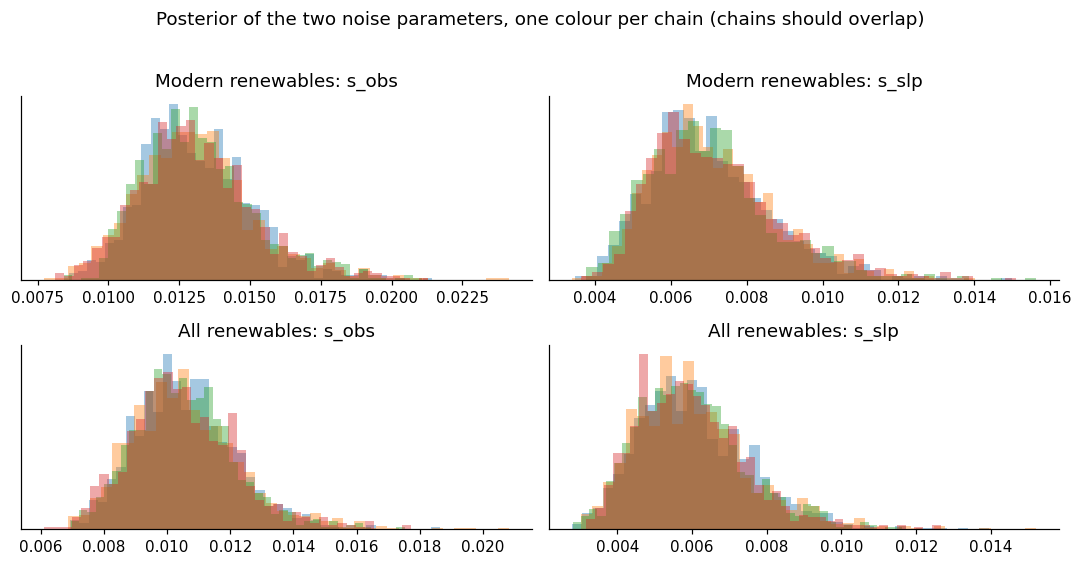

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for i, k in enumerate(SERIES):
    for j, v in enumerate(["s_obs", "s_slp"]):
        draws = idata[k].posterior.to_dataset()[v].values       # (chain, draw)
        for c in range(draws.shape[0]):
            axes[i, j].hist(draws[c], bins=40, alpha=0.4, density=True)
        axes[i, j].set(title=f"{SERIES[k][0].split(' (')[0]}: {v}", yticks=[])
plt.suptitle("Posterior of the two noise parameters, one colour per chain (chains should overlap)", y=1.02)
plt.tight_layout(); plt.show()

## 5. Does the model describe the data? Posterior checks
**(a) Fitted trend vs data**, and **(b) standardised one-step-ahead forecast errors.** If the model is adequate, each year's error should look like pure noise: mean ≈ 0, SD ≈ 1, no autocorrelation.

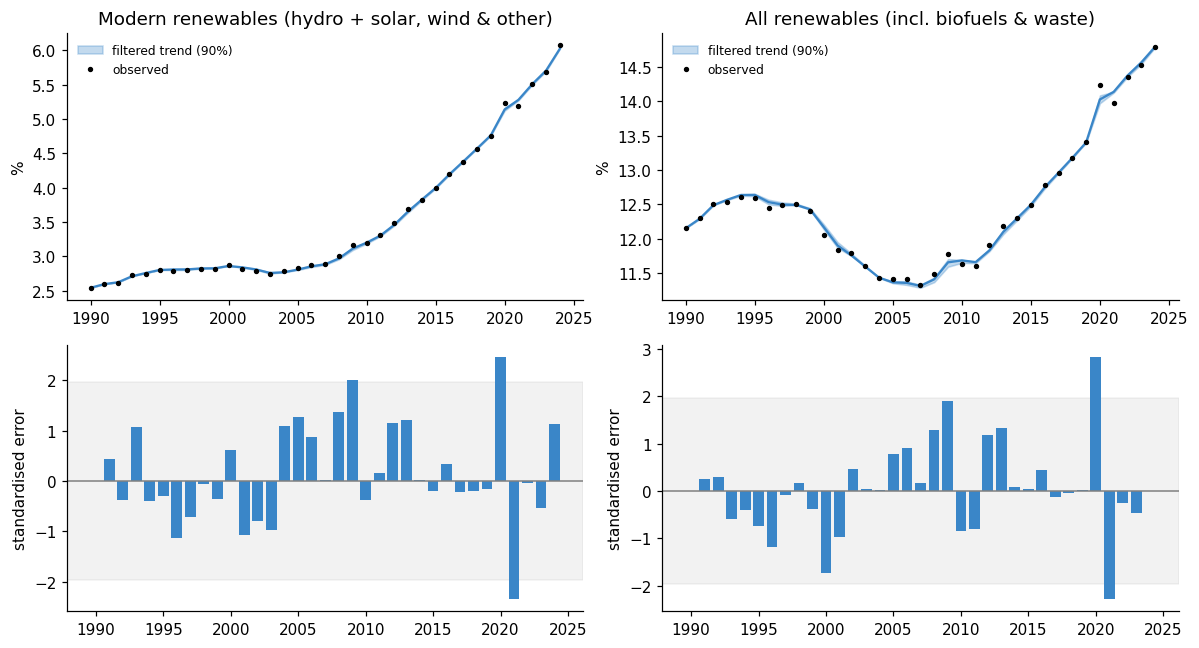

,mean,sd,lag1_autocorr,share_outside_1_96
modern_renewables,0.14,0.96,-0.04,0.09
renewables,0.04,0.95,0.02,0.06


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
checks = {}
for i, k in enumerate(SERIES):
    ds = idata[k].posterior.to_dataset()
    lvl = inv_logit(ds["level_filt"].stack(s=("chain", "draw")).values) * 100   # (T, n)
    med, lo, hi = np.median(lvl, 1), np.percentile(lvl, 5, 1), np.percentile(lvl, 95, 1)
    ax = axes[0, i]
    ax.fill_between(ej.index, lo, hi, color=COL["M2"], alpha=0.3, label="filtered trend (90%)")
    ax.plot(ej.index, med, color=COL["M2"]); ax.plot(share[k].index, share[k].values, "k.", ms=5, label="observed")
    ax.set(title=SERIES[k][0], ylabel="%"); ax.legend(frameon=False, fontsize=8)
    e = ds["std_err"].mean(("chain", "draw")).values
    checks[k] = dict(mean=e.mean(), sd=e.std(), lag1_autocorr=np.corrcoef(e[1:], e[:-1])[0, 1],
                     share_outside_1_96=float((np.abs(e) > 1.96).mean()))
    ax = axes[1, i]; ax.axhline(0, color="grey", lw=1); ax.axhspan(-1.96, 1.96, color="grey", alpha=0.1)
    ax.bar(ej.index, e, color=COL["M2"]); ax.set(ylabel="standardised error", xlabel="")
plt.tight_layout(); fig.savefig("../figures/05_model_checks.png", dpi=160); plt.show()
pd.DataFrame(checks).T

The standardised errors have mean near 0, SD near 1 and almost no lag-1 autocorrelation, so the model is not systematically missing structure in the data. (Caveat: with 35 annual points these checks are informative, not conclusive.)

## 6. Projections to 2030

In [7]:
H = list(range(2025, 2031))
fc = {(k, t): pd.read_csv(f"../results/forecast_{k}_{t}.csv").rename(columns=int)
      for k in SERIES for t in ["m1_1990", "m1_2010", "m2_smooth"]}
rows = []
for k in SERIES:
    for t, lab in [("m1_1990", "M1 linear trend, fit 1990–2024"), ("m1_2010", "M1 linear trend, fit 2010–2024"),
                   ("m2_smooth", "M2 smooth local trend (main)")]:
        s = summarize(fc[(k, t)]).loc[2030]
        rows.append({"series": SERIES[k][0].split(" (")[0], "model": lab, "2030 median %": s["median"],
                     "90% low": s["lo90"], "90% high": s["hi90"]})
proj = pd.DataFrame(rows); proj

,series,model,2030 median %,90% low,90% high
0,Modern renewables,"M1 linear trend, fit 1990–2024",6.82,6.05,7.65
1,Modern renewables,"M1 linear trend, fit 2010–2024",7.87,7.63,8.12
2,Modern renewables,M2 smooth local trend (main),7.93,6.97,9.06
3,All renewables,"M1 linear trend, fit 1990–2024",14.97,13.89,16.15
4,All renewables,"M1 linear trend, fit 2010–2024",16.48,15.93,16.97
5,All renewables,M2 smooth local trend (main),16.23,14.66,17.93


**Reading this table.** The three models disagree about 2030 by more than the narrow M1 intervals allow. For modern renewables, the M1 (1990–2024) 90% interval tops out at about 7.7%, below M2's median of 7.9%; for all renewables the same M1 interval ends at 16.2%, right at M2's median. M1 imposes one constant slope on a series whose slope has changed, so its intervals are *overconfident*, which the backtest in §8 confirms (about 17% coverage against a nominal 90%).
M2 learns how much the slope may drift and carries that into its intervals, so it is the main model. Even so, any single model's interval understates **structural (model) uncertainty**, which is why I report all three.

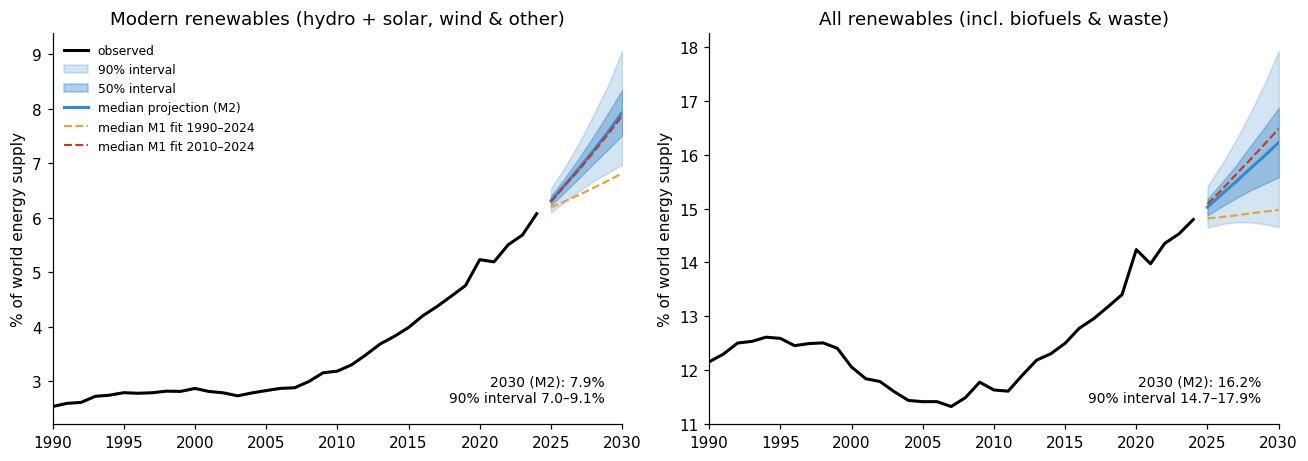

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True)
for ax, k in zip(axes, SERIES):
    d = fc[(k, "m2_smooth")]
    q = d.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).T
    ax.plot(share[k].index, share[k].values, "k-", lw=2, label="observed")
    ax.fill_between(H, q[0.05], q[0.95], color=COL["M2"], alpha=0.22, label="90% interval")
    ax.fill_between(H, q[0.25], q[0.75], color=COL["M2"], alpha=0.40, label="50% interval")
    ax.plot(H, q[0.5], color=COL["M2"], lw=2, label="median projection (M2)")
    for t, c, lab in [("m1_1990", COL["M1"], "M1 fit 1990–2024"), ("m1_2010", "#c0392b", "M1 fit 2010–2024")]:
        ax.plot(H, fc[(k, t)].median(), color=c, ls="--", lw=1.4, label=f"median {lab}")
    ax.set(title=SERIES[k][0], ylabel="% of world energy supply"); ax.set_xlim(1990, 2030)
    ax.text(0.97, 0.05, f"2030 (M2): {q.loc[2030, 0.5]:.1f}%\n90% interval {q.loc[2030, 0.05]:.1f}–{q.loc[2030, 0.95]:.1f}%",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); fig.savefig("../figures/06_projection_fan_chart.png", dpi=160); plt.show()

**Probability statements** are what a Bayesian posterior is good for: direct answers to "how likely is…?"

In [9]:
for k, thresholds in [("modern_renewables", [7, 8, 9]), ("renewables", [15, 16, 17])]:
    d = fc[(k, "m2_smooth")][2030]
    print(SERIES[k][0])
    for th in thresholds:
        print(f"   P(2030 share > {th}%) = {(d > th).mean():.0%}")
    print(f"   median {d.median():.1f}%, 90% interval {d.quantile(.05):.1f}%–{d.quantile(.95):.1f}%\n")

Modern renewables (hydro + solar, wind & other)
   P(2030 share > 7%) = 94%
   P(2030 share > 8%) = 45%
   P(2030 share > 9%) = 6%
   median 7.9%, 90% interval 7.0%–9.1%

All renewables (incl. biofuels & waste)
   P(2030 share > 15%) = 90%
   P(2030 share > 16%) = 60%
   P(2030 share > 17%) = 21%
   median 16.2%, 90% interval 14.7%–17.9%



## 7. Cross-check: two implementations of M2 must agree
The Kalman-filter version (fast) and an explicit latent-state version (slow, textbook) describe the same model. Agreement guards against an implementation bug.

In [10]:
pd.read_csv("../results/crosscheck_latent_vs_kalman.csv")

,model,s_obs,s_slp,median_2030,lo90_2030,hi90_2030
0,Kalman (marginalised),0.01,0.01,7.92,6.93,9.09
1,Latent states (explicit),0.01,0.01,7.92,6.99,9.09


## 8. Out-of-sample backtest: would these models have forecast the past well?
For each origin year (2012, 2014, 2016, 2018) I trained on data up to that year only, forecast up to six years ahead (or until 2024), and compared with what actually happened.
Metrics: **MAE** (mean absolute error of the median, in percentage points) and **90% interval coverage** (should be near 90%).

In [11]:
bt = pd.read_csv("../results/backtest_results.csv")
bt["abs_err"] = (bt["actual"] - bt["median"]).abs()
bt["covered"] = (bt["actual"] >= bt["lo90"]) & (bt["actual"] <= bt["hi90"])
bt["width"] = bt["hi90"] - bt["lo90"]
summary = (bt.groupby(["series", "model"]).agg(MAE_pp=("abs_err", "mean"), coverage_90=("covered", "mean"),
                                              mean_width_pp=("width", "mean"), n=("covered", "size")).round(2))
summary

MAE_pp  coverage_90  mean_width_pp  \
series            model                                                         
modern_renewables M0 random walk + drift     0.46         0.17           0.54   
                  M1 linear trend + AR(1)    0.54         0.17           0.65   
                  M2 smooth local trend      0.09         0.96           0.80   
renewables        M0 random walk + drift     0.84         0.17           1.04   
                  M1 linear trend + AR(1)    0.97         0.17           1.23   
                  M2 smooth local trend      0.24         0.96           1.70   

                                            n  
series            model                        
modern_renewables M0 random walk + drift   24  
                  M1 linear trend + AR(1)  24  
                  M2 smooth local trend    24  
renewables        M0 random walk + drift   24  
                  M1 linear trend + AR(1)  24  
                  M2 smooth local trend    24

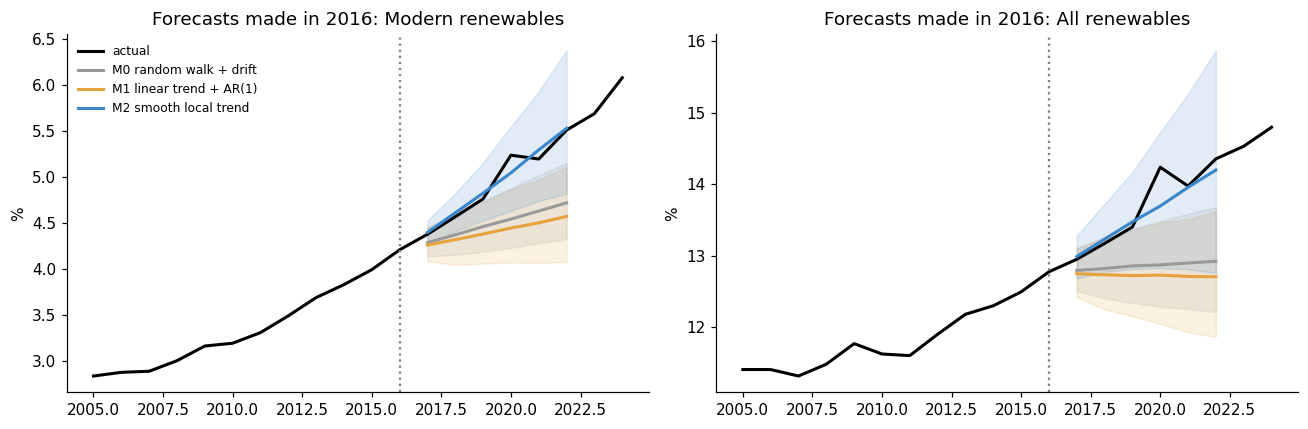

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, SERIES):
    b = bt[(bt.series == k) & (bt.origin == 2016)]
    ax.plot(share[k].loc[2005:].index, share[k].loc[2005:].values, "k-", lw=2, label="actual")
    for m_, c in zip(sorted(b.model.unique()), [COL["M0"], COL["M1"], COL["M2"]]):
        bm = b[b.model == m_].sort_values("year")
        ax.plot(bm.year, bm["median"], color=c, lw=2, label=m_)
        ax.fill_between(bm.year, bm.lo90, bm.hi90, color=c, alpha=0.15)
    ax.axvline(2016, color="grey", ls=":"); ax.set(title=f"Forecasts made in 2016: {SERIES[k][0].split(' (')[0]}", ylabel="%")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); fig.savefig("../figures/07_backtest_origin2016.png", dpi=160); plt.show()

## 9. Save the headline results

In [13]:
final = []
for k in SERIES:
    s = summarize(fc[(k, "m2_smooth")])
    s.insert(0, "series", SERIES[k][0]); s.index.name = "year"; final.append(s.reset_index())
final = pd.concat(final); final.to_csv("../results/projection_2030_summary.csv", index=False)
proj.to_csv("../results/model_sensitivity_2030.csv", index=False); summary.to_csv("../results/backtest_summary.csv")
final[final.year == 2030]

,year,series,median,lo90,hi90,mean
5,2030,"Modern renewables (hydro + solar, wind & other)",7.93,6.97,9.06,7.95
5,2030,All renewables (incl. biofuels & waste),16.23,14.66,17.93,16.25


## 10. Limitations (read before quoting any number)
- **Extrapolation, not a forecast of policy.** A trend model assumes the *process* that generated 1990–2024 continues. Policy shifts, prices or supply shocks can break that.
- **Aggregate "other renewables" category.** *Solar, wind and other renewables* mixes technologies with different growth paths; modelling them separately would be better.
- **Energy accounting method.** Shares depend on how the IEA counts non-combustible sources; they are not comparable to shares from sources that use a different method.
- **Biofuels & waste includes traditional biomass.** That is why I report modern renewables separately.
- **Small sample.** 35 annual points; backtest has only four origins with overlapping horizons (24 forecasts per model that are not independent), and the test window contains the 2020 Covid dip, so error estimates are rough.
- **Prior sensitivity not run.** The priors are diffuse (§3). I have not re-fitted with tighter or looser priors to measure how much 2030 moves.
- **Global aggregate.** Hides very different regional dynamics (e.g. sub-Saharan Africa), which is the natural next step: model by region.